## Data Preprocessing with Scanpy

In [1]:
# Core scverse libraries
from __future__ import annotations

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import math
import os

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
# Set verbosity to see more log output
sc.settings.verbosity = 4

### Reading in Data from heart droplet folder(s) into an AnnData object

In [3]:
# Load data from 10X Genomics format directory using scanpys read_10x_mtx function


# sc.read_10x_mtx("droplet/Heart-10X_P7_4"),

# checking how visualizations look when heart_droplet_annotation.csv used for cell type labels instead of annotations_droplet.csv

tiss = ad.concat([
    sc.read_10x_mtx("../droplet/Heart-10X_P7_4"),
])

tiss.obs_names_make_unique()

tiss.obs


    reading ../droplet/Heart-10X_P7_4/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.


""
AAACCTGCACGACGAA-1
AAACCTGGTTCCACGG-1
AAACCTGTCTCGATGA-1
AAACGGGAGCGCTCCA-1
AAAGCAAAGTGAATTG-1
...
TTTGGTTCAGACTCGC-1
TTTGTCAAGTGGAGAA-1
TTTGTCACAAGCCATT-1
TTTGTCAGTCGATTGT-1


In [4]:
tiss.obs

""
AAACCTGCACGACGAA-1
AAACCTGGTTCCACGG-1
AAACCTGTCTCGATGA-1
AAACGGGAGCGCTCCA-1
AAAGCAAAGTGAATTG-1
...
TTTGGTTCAGACTCGC-1
TTTGTCAAGTGGAGAA-1
TTTGTCACAAGCCATT-1
TTTGTCAGTCGATTGT-1


### Quality Control using Organ Annotation Vignette that described quality control steps done in the study 
https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-018-0590-4/MediaObjects/41586_2018_590_MOESM4_ESM.pdf

In [5]:
sc.pp.filter_cells(tiss, min_genes=500)
sc.pp.filter_cells(tiss, min_counts=1000)

tiss.obs

filtered out 30 cells that have less than 500 genes expressed


,n_genes,n_counts
AAACCTGCACGACGAA-1,2063,4680.0
AAACCTGGTTCCACGG-1,2040,4330.0
AAACCTGTCTCGATGA-1,2024,3851.0
AAACGGGAGCGCTCCA-1,1449,3902.0
AAAGCAAAGTGAATTG-1,832,1676.0
...,...,...
TTTGGTTCAGACTCGC-1,1369,3237.0
TTTGTCAAGTGGAGAA-1,2011,5522.0
TTTGTCACAAGCCATT-1,2598,7258.0
TTTGTCAGTCGATTGT-1,1912,3921.0


## Normalization

In [6]:
# Normalizing to median total counts
sc.pp.normalize_total(tiss, target_sum=1e4)

# Logarithmize the data
sc.pp.log1p(tiss)

# Scale (center to 0, unit variance)
sc.pp.scale(tiss)


normalizing counts per cell
    finished (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## Feature Selection
By including only the most informative genes. The genes that vary the most in the data.

In [7]:
sc.pp.highly_variable_genes(tiss, flavor="seurat", max_mean=math.inf, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


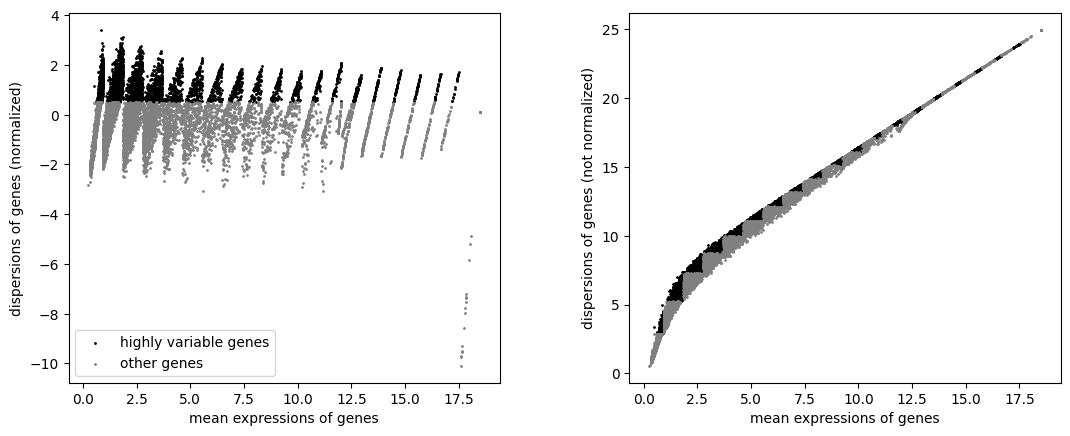

In [8]:
sc.pl.highly_variable_genes(tiss)

In [9]:
# Keep only HVGs
tiss = tiss[:, tiss.var.highly_variable]

tiss.var

,mean,std,highly_variable,means,dispersions,dispersions_norm
Sgk3,0.195018,0.429577,True,0.887148,3.254990,1.017497
Snhg6,0.215649,0.437841,True,0.906138,3.697866,1.642325
Sulf1,0.234351,0.490835,True,0.900584,3.583887,1.481519
Ncoa2,0.139505,0.378424,True,1.519065,6.171592,1.669190
Msc,0.128167,0.403610,True,1.546754,5.403806,0.726014
...,...,...,...,...,...,...
Prps2,0.120716,0.345828,True,1.356245,5.235078,0.518743
Msl3,0.260758,0.470140,True,0.784881,3.085926,0.778976
Tmlhe,0.017792,0.135171,True,6.045062,12.231495,0.700990
Zf12,0.009520,0.105516,True,9.799174,16.202242,0.790956


## Dimensionality Reduction
Through PCA

In [10]:
# PCA
sc.pp.pca(tiss)


computing PCA
    with n_comps=50
    finished (0:00:00)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PCs', the loadings (adata.varm)
    'pca_variance', the variance / eigenvalues (adata.uns['pca'])
    'pca_variance_ratio', the variance ratio (adata.uns['pca'])


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


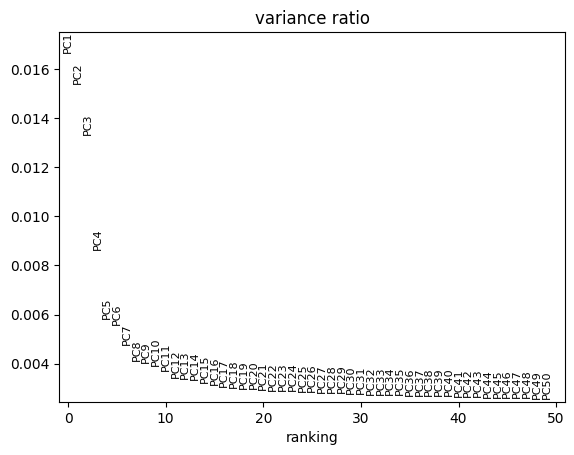

In [11]:
sc.pl.pca_variance_ratio(tiss, n_pcs=50)

## reading in annotations


In [12]:
heart_annotations = pd.read_csv("../annotations/Heart_droplet_annotation.csv")

y = heart_annotations["cell_ontology_class"].values
y


array(['endothelial cell', 'fibroblast', 'endothelial cell',
       'cardiac muscle cell', 'fibroblast', 'fibroblast', 'fibroblast',
       'cardiac muscle cell', 'endocardial cell', 'smooth muscle cell',
       'cardiac muscle cell', 'endothelial cell', 'smooth muscle cell',
       'erythrocyte', 'fibroblast', 'fibroblast', 'cardiac muscle cell',
       'endothelial cell', 'smooth muscle cell', 'erythrocyte',
       'smooth muscle cell', 'erythrocyte', 'fibroblast',
       'endothelial cell', 'cardiac muscle cell', 'endocardial cell',
       'endothelial cell', 'cardiac muscle cell', 'endocardial cell',
       'endocardial cell', 'fibroblast', 'fibroblast', 'fibroblast',
       'fibroblast', 'endothelial cell', 'fibroblast', 'fibroblast',
       'cardiac muscle cell', 'erythrocyte', 'fibroblast',
       'cardiac muscle cell', 'fibroblast', 'endothelial cell',
       'endothelial cell', 'cardiac muscle cell', 'endothelial cell',
       'endothelial cell', 'endothelial cell', 'fibroblas

In [13]:
tiss.obs["cell_ontology_class"] = y
tiss.obs

,n_genes,n_counts,cell_ontology_class
AAACCTGCACGACGAA-1,2063,4680.0,endothelial cell
AAACCTGGTTCCACGG-1,2040,4330.0,fibroblast
AAACCTGTCTCGATGA-1,2024,3851.0,endothelial cell
AAACGGGAGCGCTCCA-1,1449,3902.0,cardiac muscle cell
AAAGCAAAGTGAATTG-1,832,1676.0,fibroblast
...,...,...,...
TTTGGTTCAGACTCGC-1,1369,3237.0,cardiac muscle cell
TTTGTCAAGTGGAGAA-1,2011,5522.0,cardiac muscle cell
TTTGTCACAAGCCATT-1,2598,7258.0,endocardial cell
TTTGTCAGTCGATTGT-1,1912,3921.0,endothelial cell


## Clustering


In [14]:
# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.louvain(tiss, resolution=0.4) 

computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    computed connectivities (0:00:03)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:03)
running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 7 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)


In [15]:
#inspection based on above ouptput
tiss.obs

,n_genes,n_counts,cell_ontology_class,louvain
AAACCTGCACGACGAA-1,2063,4680.0,endothelial cell,1
AAACCTGGTTCCACGG-1,2040,4330.0,fibroblast,0
AAACCTGTCTCGATGA-1,2024,3851.0,endothelial cell,5
AAACGGGAGCGCTCCA-1,1449,3902.0,cardiac muscle cell,2
AAAGCAAAGTGAATTG-1,832,1676.0,fibroblast,0
...,...,...,...,...
TTTGGTTCAGACTCGC-1,1369,3237.0,cardiac muscle cell,4
TTTGTCAAGTGGAGAA-1,2011,5522.0,cardiac muscle cell,4
TTTGTCACAAGCCATT-1,2598,7258.0,endocardial cell,3
TTTGTCAGTCGATTGT-1,1912,3921.0,endothelial cell,1


## Visualizing Clusters Using tSNE

computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 624 samples in 0.001s...
[t-SNE] Computed neighbors for 624 samples in 0.010s...
[t-SNE] Computed conditional probabilities for sample 624 / 624
[t-SNE] Mean sigma: 3.093514
[t-SNE] KL divergence after 250 iterations with early exaggeration: 60.826317
[t-SNE] KL divergence after 1000 iterations: 0.448700
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm)
    'tsne', tSNE parameters (adata.uns) (0:00:01)


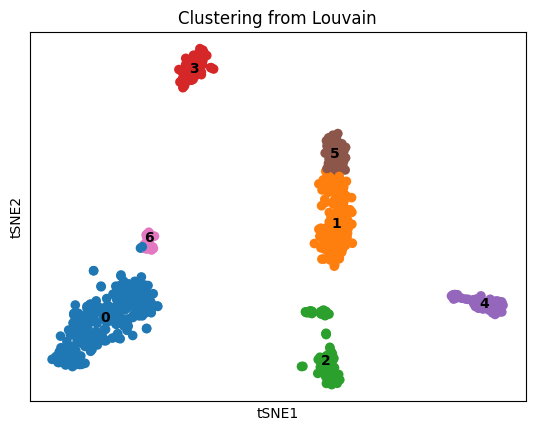

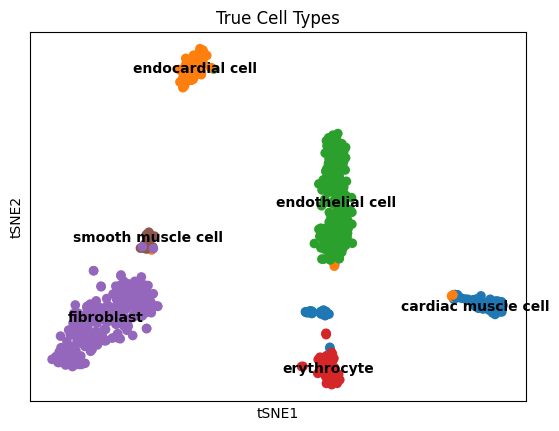

In [16]:
#computer tSNE
sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)

# Plot tSNE
sc.pl.tsne(tiss, color="louvain", title="Clustering from Louvain", legend_loc='on data')

# Plot tSNE
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')


## Machine Learning related preprocessing

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler


# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    tiss.X, y_encoded, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((499, 4658), (125, 4658), (499,), (125,))

## scikit-learn Machine Learning Classifiers

In [18]:
# --- CLASSIFIERS ---
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# optional xgboost support
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF Kernel)": SVC(probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "KNN (k=5)": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

In [20]:
from sklearn.metrics import classification_report, accuracy_score

# Train + evaluate each model
for name, model in models.items():
    model.fit(X_train, Y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(Y_test, preds)

    print("=" * 60)
    print(f"📌 Model: {name}")
    print(f"✅ Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(Y_test, preds))

📌 Model: Logistic Regression
✅ Accuracy: 0.9920

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00        32
           3       1.00      1.00      1.00        12
           4       0.98      1.00      0.99        48
           5       1.00      0.75      0.86         4

    accuracy                           0.99       125
   macro avg       1.00      0.96      0.97       125
weighted avg       0.99      0.99      0.99       125

📌 Model: SVM (RBF Kernel)
✅ Accuracy: 0.9280

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94        19
           1       1.00      1.00      1.00        10
           2       0.91      1.00      0.96        32
           3       1.00      0.75      0.86        12
           4       0.89      1.00      0.94  

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

📌 Model: Random Forest
✅ Accuracy: 0.9680

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97        19
           1       1.00      1.00      1.00        10
           2       0.97      1.00      0.98        32
           3       0.92      1.00      0.96        12
           4       0.96      1.00      0.98        48
           5       1.00      0.25      0.40         4

    accuracy                           0.97       125
   macro avg       0.98      0.87      0.88       125
weighted avg       0.97      0.97      0.96       125

📌 Model: Gradient Boosting
✅ Accuracy: 0.9680

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      0.90      0.95        10
           2       0.97      1.00      0.98        32
           3       1.00      1.00      1.00        12
           4       0.94      1.00      0.97       

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

## Pytorch Neural Network

In [21]:
import torch
from torch.utils.data import Dataset, DataLoader

# Normalize and scale
# scaler = StandardScaler(with_mean=False)
# X_scaled = scaler.fit_transform(X)
# commented out because data is already normalized and scaled using scanpy

# Convert to torch tensors
# train
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(Y_train, dtype=torch.long)
# test
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(Y_test, dtype=torch.long)



In [22]:
class SingleCellDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

dataset = SingleCellDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset, batch_size=128, shuffle=True)


In [23]:
import torch.nn as nn
import torch.nn.functional as F

class Classifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 10)
        self.fc3 = nn.Linear(10, num_classes)
        # self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        # x = self.dropout(x)
        x = F.relu(self.fc2(x))
        # x = self.dropout(x)
        x = self.fc3(x)
        return x


In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Classifier(input_dim=X_train_tensor.shape[1], num_classes=len(le.classes_)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(10):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")


Epoch 1, Loss: 1.7105
Epoch 2, Loss: 1.4542
Epoch 3, Loss: 1.2336
Epoch 4, Loss: 1.0397
Epoch 5, Loss: 0.8935
Epoch 6, Loss: 0.7821
Epoch 7, Loss: 0.6967
Epoch 8, Loss: 0.6286
Epoch 9, Loss: 0.5606
Epoch 10, Loss: 0.5009


In [25]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test_tensor.to(device)).argmax(dim=1).cpu().numpy()

acc = accuracy_score(Y_test, y_test_pred)

print("=" * 60)
print(f"📌 Model: Neural Network")
print(f"✅ Accuracy: {acc:.4f}")
print("\nClassification Report:")
print(classification_report(Y_test, y_test_pred))


📌 Model: Neural Network
✅ Accuracy: 0.9600

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90        19
           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00        32
           3       0.92      1.00      0.96        12
           4       0.98      1.00      0.99        48
           5       0.00      0.00      0.00         4

    accuracy                           0.96       125
   macro avg       0.79      0.82      0.81       125
weighted avg       0.93      0.96      0.95       125



/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

## Visualizing Model Results using TSNE

In [26]:

model.eval()
with torch.no_grad():
    preds = model(torch.tensor(tiss.X, dtype=torch.float32).to(device))
    tiss.obs["nn_pred"] = preds.argmax(1).cpu().numpy()


In [27]:
tiss.obs["nn_pred_label"] = le.inverse_transform(tiss.obs["nn_pred"])


In [28]:
import scanpy as sc

# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.leiden(tiss, resolution=3.5) 


sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)



computing neighbors
        initialized `.distances` `.connectivities` 
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)
    computed connectivities (0:00:00)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Leiden clustering
    finished: found 20 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 624 samples in 0.001s...
[t-SNE] Computed neighbors for 624 samples in 0.010s...
[t-SNE] Computed conditional probabilities for sample 624 / 624
[t-SNE] Mean sigma: 3.093514


/var/folders/wk/gl6vb2s945jbqmt08f1p2pdw0000gn/T/ipykernel_48156/845363431.py:7: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(tiss, resolution=3.5)


[t-SNE] KL divergence after 250 iterations with early exaggeration: 60.826317
[t-SNE] KL divergence after 1000 iterations: 0.448700
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm)
    'tsne', tSNE parameters (adata.uns) (0:00:01)


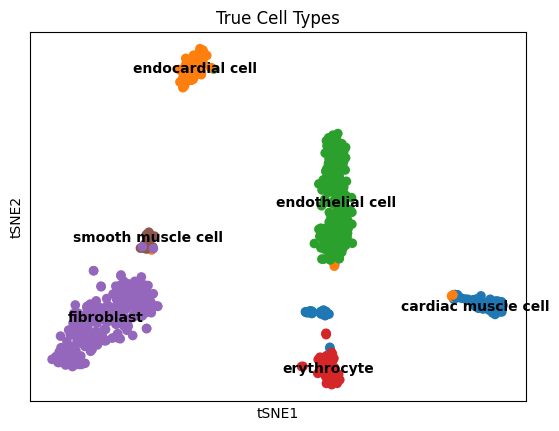

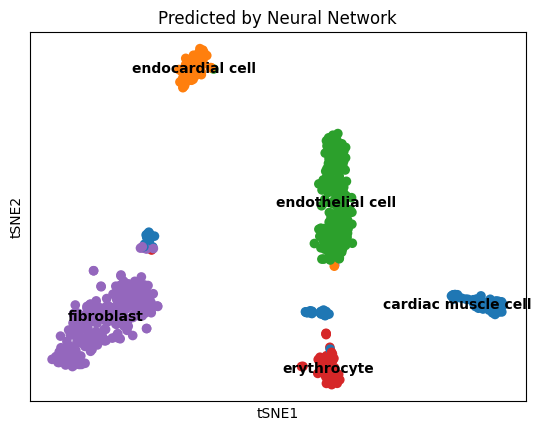

In [29]:
# True labels
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')

# Predicted labels
sc.pl.tsne(tiss, color="nn_pred_label", title="Predicted by Neural Network", legend_loc='on data')


In [30]:
tiss.obs["correct"] = (tiss.obs["nn_pred_label"] == tiss.obs["cell_ontology_class"]).astype(str)
sc.pl.tsne(tiss, color="correct", title="Correct vs Incorrect Predictions")


TypeError: Categoricals can only be compared if 'categories' are the same.